# Suivi de derive des donnees et des predictions

> **Avertissement.** Les donnees sont le jeu public IBM Telco Customer Churn,
> une photographie unique sans dates : **il n'y a aucune derive reelle a
> detecter.** Toutes les derives de ce notebook sont **INJECTEES** avec des
> parametres explicites. Les taux de detection mesurent la capacite des
> detecteurs a voir ces derives simulees ; ils ne valident pas la detection
> sur un cas reel.

Fonctions : `src/drift.py` (testees dans `tests/test_drift.py`). Rapport en
ligne de commande : `python -m src.drift_report`. Modele et seuil : ceux du
projet, lus sans modification (`models/serving_config.json`).

Ordre impose par la methode : les seuils d'alerte sont choisis **uniquement**
a partir des comparaisons sans derive (section 3), puis **figes** avant de
mesurer la detection des derives injectees (sections 4 a 6).

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import drift as dr
from src.train import RANDOM_STATE

T0 = time.time()
FIG_DIR = ROOT / "reports" / "figures"
DRIFT_DIR = ROOT / "reports" / "drift"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DRIFT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Parametres de l'etude (tous modifiables)
N_DRAWS = 1000            # redecoupages aleatoires par configuration
CONVENTION = dr.Thresholds(psi_watch=0.10, psi_alert=0.25, alpha=0.05)
# Taux de fausses alertes acceptes, fixes AVANT toute mesure (part des
# comparaisons sans derive qui declenchent au moins un signal) :
TARGET_FALSE_WATCH = 0.10   # niveau surveillance
TARGET_FALSE_ALERT = 0.01   # niveau alerte
# Intensites des derives INJECTEES
TENURE_SHIFTS = [3, 6, 12]               # mois retires a l'anciennete
PRICE_INCREASES = [0.02, 0.05, 0.10]     # hausse de MonthlyCharges
MONTH_TO_MONTH_SHARES = [0.65, 0.75, 0.85]  # part cible de contrats mensuels
CONCEPT_FLIPS = [0.10, 0.20, 0.30]       # part des non-churners anciens devenus churners
# Graines fixes, derivees de celle du projet (42) : une par usage.
SEED_SPLIT, SEED_CONTRACT, SEED_CONCEPT = (RANDOM_STATE + i for i in range(3))

In [2]:
config = json.loads((ROOT / "models" / "serving_config.json").read_text())
THRESHOLD = config["threshold"]
split = joblib.load(ROOT / "models" / "test_split.pkl")
model = joblib.load(ROOT / config["model_path"])
X_train, X_test = split["X_train"], split["X_test"]
y_train, y_test = split["y_train"].to_numpy(), split["y_test"].to_numpy()
p_train, p_test = model.predict_proba(X_train)[:, 1], model.predict_proba(X_test)[:, 1]
NUMERIC, CATEGORICAL = dr.drift_columns(X_train)
print(f"Modele : {config['model_path']} ; seuil de decision : {THRESHOLD}")
print(f"Reference = train : {len(X_train)} clients ; jeu courant = test : {len(X_test)} clients")
print(f"Variables surveillees : {len(NUMERIC)} numeriques {NUMERIC}, {len(CATEGORICAL)} categorielles "
      f"(SeniorCitizen, binaire, traitee comme categorielle)")

Modele : models/calibrated_model.pkl ; seuil de decision : 0.18
Reference = train : 5634 clients ; jeu courant = test : 1409 clients
Variables surveillees : 3 numeriques ['tenure', 'MonthlyCharges', 'TotalCharges'], 16 categorielles (SeniorCitizen, binaire, traitee comme categorielle)


## 1. Mesures utilisees

- **PSI** (indice de stabilite de population) : compare la repartition d'une
  variable entre reference et courant, sur des classes fixees sur la
  reference (deciles pour une numerique, modalites pour une categorielle).
  0 = repartitions identiques. Les classes vides sont lissees (1e-4), une
  modalite inconnue de la reference compte comme une classe.
- **Test** : Kolmogorov-Smirnov (numeriques), chi-deux d'homogeneite
  (categorielles). 19 variables testees a la fois : les valeurs p sont
  corrigees par **Benjamini-Hochberg**, sinon environ une variable sur vingt
  serait signalee par hasard.
- **Niveaux** (convention d'usage, pas une regle) : *alerte* si PSI >= 0,25
  et p corrigee < 0,05 ; *surveillance* si PSI >= 0,1 ou p corrigee < 0,05 ;
  sinon *aucun*. Le PSI mesure la taille de l'ecart, la valeur p dit s'il
  depasse le hasard.
- **Predictions** : PSI et KS sur la probabilite predite, et part des clients
  au-dessus du seuil 0,18 (les clients que la campagne contacterait).

## 2. Reference contre test reel : aucune derive attendue

Le test est un echantillon aleatoire stratifie du meme jeu que le train :
aucune derive n'est attendue. Une seule comparaison ne dit pas a quelle
frequence les detecteurs se trompent ; on le mesure ensuite sur `N_DRAWS`
redecoupages aleatoires des 7 043 clients en une reference de la taille du
train et un courant de la taille du test.

In [3]:
real = dr.feature_drift(X_train, X_test, NUMERIC, CATEGORICAL, CONVENTION)
real_pred = dr.prediction_drift(p_train, p_test, THRESHOLD, CONVENTION)
display(real.sort_values("psi", ascending=False).head(8))
print(f"Variables signalees (convention) : {real.loc[real['level'] != 'aucun', 'variable'].tolist() or 'aucune'}"
      f" ; PSI maximal {real['psi'].max():.4f}")
print(f"Predictions : PSI {real_pred['psi']:.4f}, KS p = {real_pred['p_value']:.3f}, part >= {THRESHOLD} : "
      f"{real_pred['share_above_ref']:.2%} (train) contre {real_pred['share_above_cur']:.2%} (test) ; "
      f"niveau {real_pred['level']}")

,variable,type,test,psi,statistic,p_value,p_adjusted,level
1,MonthlyCharges,numerique,ks,0.0129,0.0321,0.1912,0.7956,aucun
2,TotalCharges,numerique,ks,0.0075,0.0296,0.2710,0.8580,aucun
0,tenure,numerique,ks,0.0058,0.0212,0.6835,0.9291,aucun
11,OnlineBackup,categorielle,chi2,0.0044,4.9367,0.0847,0.7956,aucun
8,MultipleLines,categorielle,chi2,0.0030,3.3552,0.1868,0.7956,aucun
14,StreamingTV,categorielle,chi2,0.0028,3.1273,0.2094,0.7956,aucun
7,PhoneService,categorielle,chi2,0.0017,1.8321,0.1759,0.7956,aucun
15,StreamingMovies,categorielle,chi2,0.0010,1.1532,0.5618,0.9291,aucun


Variables signalees (convention) : aucune ; PSI maximal 0.0129
Predictions : PSI 0.0139, KS p = 0.703, part >= 0.18 : 51.77% (train) contre 52.24% (test) ; niveau aucun


In [4]:
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = np.r_[y_train, y_test]
p_all = np.r_[p_train, p_test]
N_ALL, N_CUR = len(X_all), len(X_test)
sim = dr.DriftSimulator(X_all, p_all, THRESHOLD)
VARIABLES = sim.variables
splits = [dr.random_split(N_ALL, N_CUR, [SEED_SPLIT, i]) for i in range(N_DRAWS)]

t = time.time()
enc_all = sim.encode(X_all)
null = [sim.evaluate(r, enc_all, p_all, c, CONVENTION) for r, c in splits]
T_NULL = time.time() - t
null_psi = np.array([d["psi"] for d in null])                 # tirages x variables
null_padj = np.array([d["p_adjusted"] for d in null])
null_pred_psi = np.array([d["prediction"]["psi"] for d in null])
null_pred_p = np.array([d["prediction"]["p_value"] for d in null])
print(f"{N_DRAWS} redecoupages sans derive en {T_NULL:.0f} s")


def levels_under(th: dr.Thresholds):
    """Niveaux des tirages sans derive pour des seuils donnes (sans recalcul des tests)."""
    feat = np.vectorize(lambda s, p: dr.LEVELS.index(dr.alert_level(s, p, th)))(null_psi, null_padj)
    pred = np.vectorize(lambda s, p: dr.LEVELS.index(dr.alert_level(s, p, th)))(null_pred_psi, null_pred_p)
    return feat, pred


def false_alert_table(th: dr.Thresholds) -> pd.DataFrame:
    feat, pred = levels_under(th)
    overall = np.maximum(feat.max(axis=1), pred)
    rows = []
    for name, lv in (("au moins une variable ou les predictions", overall),
                     ("au moins une variable", feat.max(axis=1)), ("predictions", pred)):
        for k, level in ((1, "surveillance ou plus"), (2, "alerte")):
            r = dr.rate_with_se(int((lv >= k).sum()), N_DRAWS)
            rows.append({"signal": name, "niveau": level, "fausses_alertes": r["rate"], "erreur_type": r["se"]})
    return pd.DataFrame(rows)


far_convention = false_alert_table(CONVENTION)
display(far_convention)

1000 redecoupages sans derive en 59 s


,signal,niveau,fausses_alertes,erreur_type
0,au moins une variable ou les predictions,surveillance ou plus,0.0840,0.0088
1,au moins une variable ou les predictions,alerte,0.0000,0.0000
2,au moins une variable,surveillance ou plus,0.0330,0.0056
3,au moins une variable,alerte,0.0000,0.0000
4,predictions,surveillance ou plus,0.0550,0.0072
5,predictions,alerte,0.0000,0.0000


Taux de fausses alertes **par variable** (part des redecoupages sans derive
ou la variable est signalee), avec la convention :

In [5]:
feat_conv, _ = levels_under(CONVENTION)
per_var = pd.DataFrame({
    "variable": VARIABLES,
    "surveillance_ou_plus": (feat_conv >= 1).mean(axis=0),
    "alerte": (feat_conv >= 2).mean(axis=0),
    "psi_null_moyen": null_psi.mean(axis=0),
    "psi_null_p99": np.quantile(null_psi, 0.99, axis=0),
})
per_var["erreur_type_surveillance"] = np.sqrt(per_var["surveillance_ou_plus"]
                                              * (1 - per_var["surveillance_ou_plus"]) / N_DRAWS)
display(per_var.sort_values("surveillance_ou_plus", ascending=False))

,variable,surveillance_ou_plus,alerte,psi_null_moyen,psi_null_p99,erreur_type_surveillance
7,PhoneService,0.0070,0.0000,0.0009,0.0062,0.0026
14,StreamingTV,0.0060,0.0000,0.0017,0.0084,0.0024
8,MultipleLines,0.0050,0.0000,0.0017,0.0084,0.0022
15,StreamingMovies,0.0040,0.0000,0.0018,0.0083,0.0020
13,TechSupport,0.0040,0.0000,0.0017,0.0074,0.0020
2,TotalCharges,0.0040,0.0000,0.0078,0.0180,0.0020
4,SeniorCitizen,0.0040,0.0000,0.0009,0.0059,0.0020
9,InternetService,0.0040,0.0000,0.0018,0.0077,0.0020
12,DeviceProtection,0.0040,0.0000,0.0017,0.0078,0.0020
11,OnlineBackup,0.0040,0.0000,0.0016,0.0074,0.0020


## 3. Choix et gel des seuils d'alerte (avant toute derive injectee)

Regle fixee a l'avance, appliquee aux seuls redecoupages sans derive :
on garde la convention si elle donne au plus `TARGET_FALSE_WATCH` (10 %) de
fausses alertes au niveau surveillance et `TARGET_FALSE_ALERT` (1 %) au niveau
alerte ; sinon le seuil PSI est remonte au quantile correspondant du PSI
maximal observe sans derive (`choose_psi_threshold`). Le seuil de la valeur p
(0,05 apres Benjamini-Hochberg) n'est pas modifie. **Les scenarios injectes
ne servent jamais a ce choix** : ils sont evalues apres, avec ces seuils figes.

In [6]:
null_max_psi = np.maximum(null_psi.max(axis=1), null_pred_psi)
FROZEN = dr.Thresholds(
    psi_watch=dr.choose_psi_threshold(null_max_psi, TARGET_FALSE_WATCH, CONVENTION.psi_watch),
    psi_alert=dr.choose_psi_threshold(null_max_psi, TARGET_FALSE_ALERT, CONVENTION.psi_alert),
    alpha=CONVENTION.alpha,
)
far_frozen = false_alert_table(FROZEN)
watch_ok = far_frozen.iloc[0]["fausses_alertes"] <= TARGET_FALSE_WATCH
alert_ok = far_frozen.iloc[1]["fausses_alertes"] <= TARGET_FALSE_ALERT
print(f"PSI maximal sans derive : mediane {np.median(null_max_psi):.4f}, quantile 99 % "
      f"{np.quantile(null_max_psi, 0.99):.4f}, maximum {null_max_psi.max():.4f}")
print(f"Seuils figes : {FROZEN.as_dict()} "
      f"({'convention conservee' if FROZEN == CONVENTION else 'convention remontee'})")
print(f"Fausses alertes avec ces seuils : surveillance {far_frozen.iloc[0]['fausses_alertes']:.1%} "
      f"(cible <= {TARGET_FALSE_WATCH:.0%} : {'tenue' if watch_ok else 'NON tenue'}), alerte "
      f"{far_frozen.iloc[1]['fausses_alertes']:.1%} (cible <= {TARGET_FALSE_ALERT:.0%} : "
      f"{'tenue' if alert_ok else 'NON tenue'})")

(DRIFT_DIR / "alert_thresholds.json").write_text(json.dumps({
    **FROZEN.as_dict(),
    "source": "notebooks/03_drift_monitoring : redecoupages sans derive uniquement",
    "n_draws": N_DRAWS,
    "targets": {"surveillance": TARGET_FALSE_WATCH, "alerte": TARGET_FALSE_ALERT},
    "false_alert_rate": {"surveillance": round(float(far_frozen.iloc[0]["fausses_alertes"]), 4),
                         "alerte": round(float(far_frozen.iloc[1]["fausses_alertes"]), 4)},
}, indent=2) + "\n", encoding="utf-8")
print(f"Seuils ecrits dans {DRIFT_DIR.relative_to(ROOT) / 'alert_thresholds.json'} (lus par src.drift_report)")

PSI maximal sans derive : mediane 0.0114, quantile 99 % 0.0215, maximum 0.0324
Seuils figes : {'psi_watch': 0.1, 'psi_alert': 0.25, 'alpha': 0.05} (convention conservee)
Fausses alertes avec ces seuils : surveillance 8.4% (cible <= 10% : tenue), alerte 0.0% (cible <= 1% : tenue)
Seuils ecrits dans reports\drift\alert_thresholds.json (lus par src.drift_report)


Le niveau surveillance a un plancher qu'aucun seuil PSI ne supprime : sans
derive, Benjamini-Hochberg garde au plus environ alpha (5 %) de redecoupages
avec au moins une variable significative, et les predictions, testees a part
et sans correction, ajoutent environ alpha. Les deux s'additionnent presque
(tableau ci-dessus). C'est le prix du declenchement par la valeur p seule ;
le niveau alerte, qui exige aussi un PSI eleve, est bien plus rare.

**Erreurs-types.** Ce sont des erreurs de Monte-Carlo : elles disent avec
quelle precision `N_DRAWS` tirages estiment un taux **sur ce jeu**. Les
redecoupages reutilisent les memes 7 043 clients ; ces erreurs ne mesurent
pas l'incertitude sur une autre population ou une autre periode.

## 4. Scenarios de derive INJECTEE

Chaque derive est appliquee **une fois** a l'ensemble des 7 043 clients
(graine fixe), et le modele servi score cette version modifiee. Chaque
tirage reprend ensuite **le meme redecoupage** qu'en section 2 : la
reference vient des donnees d'origine, le courant de la version modifiee.

| Scenario | Ce qui change | Intensites |
|---|---|---|
| Anciennete | `tenure` baisse de k mois (bornee a 0), `TotalCharges` ajuste au prorata : afflux de clients recents | 3, 6, 12 mois |
| Prix | `MonthlyCharges` augmente (hausse tarifaire) ; `TotalCharges`, deja facture, ne change pas | +2 %, +5 %, +10 % |
| Contrats | part de contrats mensuels portee a la cible, par reaffectation au hasard de contrats 1 ou 2 ans | 65 %, 75 %, 85 % |
| Conceptuelle | **X inchange** ; parmi les clients d'anciennete superieure a la mediane du train, une part des non-churners devient churner | 10 %, 20 %, 30 % |

**Limite du scenario Contrats** : seule la colonne `Contract` change. Dans la
realite, un client mensuel a en moyenne moins d'anciennete et un autre prix ;
ici ces variables ne suivent pas, ce qui rend la derive plus simple a isoler
(une seule variable touchee) et moins realiste.

In [7]:
SCENARIOS = {
    "anciennete": ([f"-{k} mois" for k in TENURE_SHIFTS], [lambda X, k=k: dr.inject_tenure_shift(X, k)
                                                          for k in TENURE_SHIFTS], ["tenure", "TotalCharges"]),
    "prix": ([f"+{x:.0%}" for x in PRICE_INCREASES], [lambda X, x=x: dr.inject_monthly_charges_increase(X, x)
                                                      for x in PRICE_INCREASES], ["MonthlyCharges"]),
    "contrats": ([f"{s:.0%} mensuels" for s in MONTH_TO_MONTH_SHARES],
                 [lambda X, s=s: dr.inject_contract_mix(X, s, SEED_CONTRACT) for s in MONTH_TO_MONTH_SHARES],
                 ["Contract"]),
}
mtm_share = (X_all["Contract"] == "Month-to-month").mean()
print(f"Part de contrats mensuels avant injection : {mtm_share:.1%}")

t = time.time()
detections, flagged_counts = [], {}
for scenario, (labels, injectors, injected_vars) in SCENARIOS.items():
    for label, inject in zip(labels, injectors):
        X_inj = inject(X_all)
        p_inj = model.predict_proba(X_inj)[:, 1]
        enc = sim.encode(X_inj)
        draws = [sim.evaluate(r, enc, p_inj, c, FROZEN) for r, c in splits]
        lv = np.array([[dr.LEVELS.index(x) for x in d["levels"]] for d in draws])
        overall = np.array([dr.LEVELS.index(d["overall_level"]) for d in draws])
        pred = np.array([dr.LEVELS.index(d["prediction"]["level"]) for d in draws])
        inj_cols = [VARIABLES.index(v) for v in injected_vars]
        row = {"scenario": scenario, "intensite": label}
        for k, name in ((1, "surveillance"), (2, "alerte")):
            r = dr.rate_with_se(int((overall >= k).sum()), N_DRAWS)
            row[f"detection_{name}"], row[f"se_{name}"] = r["rate"], r["se"]
            row[f"variable_injectee_{name}"] = float((lv[:, inj_cols].max(axis=1) >= k).mean())
            row[f"predictions_{name}"] = float((pred >= k).mean())
        row["psi_moyen_variable_injectee"] = float(np.mean([d["psi"][inj_cols].max() for d in draws]))
        row["psi_moyen_predictions"] = float(np.mean([d["prediction"]["psi"] for d in draws]))
        row["part_au_dessus_seuil"] = float(np.mean([d["prediction"]["share_above_cur"] for d in draws]))
        detections.append(row)
        flagged_counts[(scenario, label)] = pd.Series((lv >= 1).mean(axis=0), index=VARIABLES)
T_SCEN = time.time() - t
print(f"{len(detections)} configurations x {N_DRAWS} tirages en {T_SCEN:.0f} s")

Part de contrats mensuels avant injection : 55.0%


9 configurations x 1000 tirages en 928 s


## 5. Taux de detection par scenario et intensite (seuils figes)

Taux de detection = part des tirages ou au moins une variable ou les
predictions atteignent le niveau indique. Erreur-type binomiale
sqrt(p(1 - p) / N_DRAWS). Pour comparaison, sans derive, ce taux vaut le
taux de fausses alertes de la section 3.

In [8]:
det = pd.DataFrame(detections)
reference_row = {"scenario": "aucune derive", "intensite": "0",
                 "detection_surveillance": far_frozen.iloc[0]["fausses_alertes"],
                 "se_surveillance": far_frozen.iloc[0]["erreur_type"],
                 "detection_alerte": far_frozen.iloc[1]["fausses_alertes"],
                 "se_alerte": far_frozen.iloc[1]["erreur_type"]}
display(pd.concat([pd.DataFrame([reference_row]), det], ignore_index=True)[
    ["scenario", "intensite", "detection_surveillance", "se_surveillance", "detection_alerte", "se_alerte",
     "variable_injectee_surveillance", "variable_injectee_alerte", "psi_moyen_variable_injectee"]])

,scenario,intensite,detection_surveillance,se_surveillance,detection_alerte,se_alerte,variable_injectee_surveillance,variable_injectee_alerte,psi_moyen_variable_injectee
0,aucune derive,0,0.0840,0.0088,0.0000,0.0000,NaN,NaN,NaN
1,anciennete,-3 mois,1.0000,0.0000,0.9990,0.0010,1.0000,0.9990,0.7047
2,anciennete,-6 mois,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.7437
3,anciennete,-12 mois,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,1.6425
4,prix,+2%,0.5830,0.0156,0.0000,0.0000,0.5310,0.0000,0.0748
5,prix,+5%,1.0000,0.0000,0.9970,0.0017,1.0000,0.9970,0.3540
6,prix,+10%,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.8591
7,contrats,65% mensuels,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0431
8,contrats,75% mensuels,1.0000,0.0000,0.0020,0.0014,1.0000,0.0020,0.1799
9,contrats,85% mensuels,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.4626


**Lecture du scenario Anciennete.** Le decalage est borne a 0 : les clients
de moins de k mois passent tous a 0 mois, valeur quasi absente de la
reference (clients tout juste arrives). Cette masse a 0 pese lourd dans le
PSI, des 3 mois. Un vrai afflux de nouveaux clients aurait une forme plus
progressive.

Variables signalees (niveau surveillance ou plus), en part des tirages. Les
variables qui ne sont pas injectees ne doivent etre signalees qu'au niveau
des fausses alertes ; `TotalCharges` suit `tenure` par construction.

In [9]:
flags = pd.DataFrame(flagged_counts).T
flags.index.names = ["scenario", "intensite"]
top = flags.loc[:, (flags > 0.05).any(axis=0)]
display(top)

tenure  MonthlyCharges  TotalCharges  Contract
scenario   intensite                                                   
anciennete -3 mois       1.0000          0.0050        1.0000    0.0050
           -6 mois       1.0000          0.0050        1.0000    0.0050
           -12 mois      1.0000          0.0050        1.0000    0.0050
prix       +2%           0.0030          0.5310        0.0060    0.0030
           +5%           0.0030          1.0000        0.0060    0.0040
           +10%          0.0030          1.0000        0.0060    0.0040
contrats   65% mensuels  0.0030          0.0030        0.0060    1.0000
           75% mensuels  0.0030          0.0030        0.0060    1.0000
           85% mensuels  0.0030          0.0030        0.0060    1.0000

## 6. Derive des predictions et performance a etiquettes retardees

Une derive des donnees ne compte que si elle change les decisions. Ci-dessous :
PSI des probabilites predites et part des clients au-dessus du seuil 0,18
(clients contactes), par scenario.

In [10]:
display(det[["scenario", "intensite", "psi_moyen_predictions", "predictions_surveillance",
             "predictions_alerte", "part_au_dessus_seuil"]])
print(f"Sans derive : part au-dessus du seuil {(p_all >= THRESHOLD).mean():.2%} "
      f"sur les 7 043 clients")

,scenario,intensite,psi_moyen_predictions,predictions_surveillance,predictions_alerte,part_au_dessus_seuil
0,anciennete,-3 mois,0.0124,0.2730,0.0000,0.5363
1,anciennete,-6 mois,0.0188,0.7150,0.0000,0.5510
2,anciennete,-12 mois,0.0433,0.9970,0.0000,0.5798
3,prix,+2%,0.0084,0.0730,0.0000,0.5120
4,prix,+5%,0.0110,0.1930,0.0000,0.5038
5,prix,+10%,0.0191,0.6580,0.0000,0.4896
6,contrats,65% mensuels,0.0148,0.4960,0.0000,0.5384
7,contrats,75% mensuels,0.0374,0.9970,0.0000,0.5588
8,contrats,85% mensuels,0.0843,1.0000,0.0000,0.5784


Sans derive : part au-dessus du seuil 51.87% sur les 7 043 clients


**Derive conceptuelle.** Les variables ne changent pas : les detecteurs sur
X et sur les predictions donnent **exactement** les resultats sans derive
(memes redecoupages, memes donnees, donc meme taux de « detection » que le
taux de fausses alertes). Seules les **etiquettes**, connues plus tard
(le churn se constate apres coup), revelent le probleme : on mesure le rappel
et la precision de la decision servie (seuil 0,18) sur le jeu courant.

In [11]:
tenure_cut = float(np.median(X_train["tenure"]))
perf_rows = []
for flip in [0.0, *CONCEPT_FLIPS]:
    y_drift = dr.inject_concept_drift(X_all, y_all, flip, tenure_cut, SEED_CONCEPT) if flip else y_all
    perfs = pd.DataFrame([dr.performance_at_threshold(y_drift[c], p_all[c], THRESHOLD) for _, c in splits])
    perf_rows.append({
        "part_basculee": flip,
        "churn_courant": perfs["churn_rate"].mean(),
        "rappel": perfs["recall"].mean(), "se_rappel": perfs["recall"].std(ddof=1) / np.sqrt(N_DRAWS),
        "precision": perfs["precision"].mean(),
        "se_precision": perfs["precision"].std(ddof=1) / np.sqrt(N_DRAWS),
        "part_contactee": perfs["contacted_share"].mean(),
    })
perf = pd.DataFrame(perf_rows)
print(f"Coupure d'anciennete : {tenure_cut:.0f} mois (mediane du train) ; "
      f"detection sur X et predictions : identique au cas sans derive "
      f"({far_frozen.iloc[0]['fausses_alertes']:.1%} au niveau surveillance)")
display(perf)

Coupure d'anciennete : 29 mois (mediane du train) ; detection sur X et predictions : identique au cas sans derive (8.4% au niveau surveillance)


,part_basculee,churn_courant,rappel,se_rappel,precision,se_precision,part_contactee
0,0.0000,0.2649,0.8940,0.0005,0.4568,0.0005,0.5183
1,0.1000,0.3055,0.7986,0.0006,0.4707,0.0005,0.5183
2,0.2000,0.3462,0.7313,0.0006,0.4885,0.0005,0.5183
3,0.3000,0.3904,0.6755,0.0006,0.5088,0.0005,0.5183


**Lecture.** Le rappel compare a la ligne 0 % montre combien de churners la
decision servie manque quand la relation anciennete-churn change. La
precision peut monter mecaniquement : le churn de base augmente, donc une
plus grande part des clients contactes sont des churners. Une seule metrique
ne suffit pas a juger la performance. Les erreurs-types, tres petites, sont
des erreurs de Monte-Carlo sur des tirages qui se recouvrent (voir section 3),
pas des intervalles d'incertitude du rappel sur de nouveaux clients.

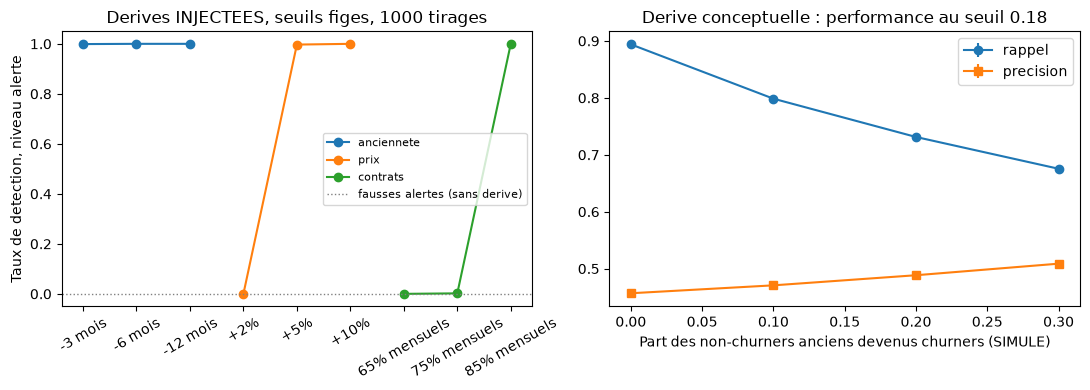

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for scenario, group in det.groupby("scenario", sort=False):
    axes[0].plot(group["intensite"], group["detection_alerte"], "o-", label=scenario)
axes[0].axhline(far_frozen.iloc[1]["fausses_alertes"], color="grey", ls=":", lw=1,
                label="fausses alertes (sans derive)")
axes[0].set_ylabel("Taux de detection, niveau alerte")
axes[0].set_title(f"Derives INJECTEES, seuils figes, {N_DRAWS} tirages")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
axes[1].errorbar(perf["part_basculee"], perf["rappel"], yerr=1.96 * perf["se_rappel"], fmt="o-", label="rappel")
axes[1].errorbar(perf["part_basculee"], perf["precision"], yerr=1.96 * perf["se_precision"], fmt="s-",
                 label="precision")
axes[1].set_xlabel("Part des non-churners anciens devenus churners (SIMULE)")
axes[1].set_title(f"Derive conceptuelle : performance au seuil {THRESHOLD}")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_detection.png", dpi=120)
plt.show()

## 7. Conclusion

**Ce que le notebook montre** : sur ce jeu, une chaine de suivi de derive
(PSI, tests corriges par Benjamini-Hochberg, niveaux d'alerte) dont le taux de
fausses alertes est mesure sur des redecoupages sans derive, avec des seuils
choisis et figes sur cette seule base ; puis sa capacite a detecter des
derives **injectees** de differentes intensites sur les variables et sur les
predictions. La derive conceptuelle illustre la limite principale : elle est
invisible pour des detecteurs qui ne regardent que X et les predictions, et
n'apparait qu'avec les etiquettes, connues en retard.

**Ce qu'il ne montre pas** : la detection d'une derive reelle. Les derives
sont simulees, avec des mecanismes simples (une ou deux variables modifiees a
la fois, sans les correlations d'un vrai changement de clientele) ; un seul
jeu, statique ; des seuils PSI de convention, verifies ici seulement contre
le taux de fausses alertes de ce jeu et de ces tailles d'echantillon.

**En production, il faudrait** : une reference figee (donnees d'entrainement
ou une periode stable) et des fenetres courantes datees ; des taux de fausses
alertes mesures sur des periodes historiques stables ; un suivi des
etiquettes retardees (rappel, precision, calibration) des qu'elles arrivent ;
l'historique des metriques (ici MLflow local) avec alerte vers une equipe ;
une procedure de decision (analyse, reentrainement, recalibration du seuil),
jamais un reentrainement automatique sur simple alerte.

In [13]:
print("Chiffres de cette execution :")
print(f"- fausses alertes (au moins une variable ou les predictions), {N_DRAWS} tirages : surveillance "
      f"{far_frozen.iloc[0]['fausses_alertes']:.1%} (+/- {far_frozen.iloc[0]['erreur_type']:.1%}), alerte "
      f"{far_frozen.iloc[1]['fausses_alertes']:.1%} (+/- {far_frozen.iloc[1]['erreur_type']:.1%})")
print(f"- seuils figes : {FROZEN.as_dict()}")
for _, row in det.iterrows():
    print(f"- {row['scenario']} {row['intensite']} (SIMULE) : detection surveillance "
          f"{row['detection_surveillance']:.1%}, alerte {row['detection_alerte']:.1%}")
for _, row in perf.iterrows():
    print(f"- derive conceptuelle {row['part_basculee']:.0%} (SIMULEE) : rappel {row['rappel']:.3f}, "
          f"precision {row['precision']:.3f}")
print(f"Temps d'execution du notebook : {time.time() - T0:.0f} s "
      f"(dont {T_NULL:.0f} s sans derive et {T_SCEN:.0f} s pour les scenarios)")

Chiffres de cette execution :
- fausses alertes (au moins une variable ou les predictions), 1000 tirages : surveillance 8.4% (+/- 0.9%), alerte 0.0% (+/- 0.0%)
- seuils figes : {'psi_watch': 0.1, 'psi_alert': 0.25, 'alpha': 0.05}
- anciennete -3 mois (SIMULE) : detection surveillance 100.0%, alerte 99.9%
- anciennete -6 mois (SIMULE) : detection surveillance 100.0%, alerte 100.0%
- anciennete -12 mois (SIMULE) : detection surveillance 100.0%, alerte 100.0%
- prix +2% (SIMULE) : detection surveillance 58.3%, alerte 0.0%
- prix +5% (SIMULE) : detection surveillance 100.0%, alerte 99.7%
- prix +10% (SIMULE) : detection surveillance 100.0%, alerte 100.0%
- contrats 65% mensuels (SIMULE) : detection surveillance 100.0%, alerte 0.0%
- contrats 75% mensuels (SIMULE) : detection surveillance 100.0%, alerte 0.2%
- contrats 85% mensuels (SIMULE) : detection surveillance 100.0%, alerte 100.0%
- derive conceptuelle 0% (SIMULEE) : rappel 0.894, precision 0.457
- derive conceptuelle 10% (SIMULEE) : 